### PROJETO AVALIATIVO — MÓDULO 1
### Arquivo: `3_analise.ipynb` — Camada Gold
**Projeto:** Viagens a Serviço — Portal da Transparência  
**Arquitetura:** Raw → Silver → Gold

### Objetivo do notebook

Este notebook corresponde à Fase 3 do pipeline de dados. A partir das tabelas da camada **Silver**, preparadas no arquivo `2_transformar.py`, serão realizadas consultas SQL, análises de negócio e visualizações gráficas, além da construção da camada **Gold**, com tabelas e *views* agregadas.

As atividades desta etapa são:

1. Consultar e analisar os dados da camada Silver.
2. Criar a camada Gold, com tabelas e *views* para análises agregadas.
3. Responder às perguntas de negócio utilizando consultas SQL e tabelas.
4. Criar gráficos para facilitar a interpretação dos resultados.
5. Apresentar conclusões com base nos dados analisados.

### Atenção: ordem de execução

Antes de executar este notebook, certifique-se de que os seguintes arquivos foram executados:

- `0_criar_banco.sql` — criação da estrutura do banco de dados.
- `1_extrair.py` — extração e carga dos dados na camada Raw.
- `2_transformar.py` — limpeza, tratamento e carga dos dados na camada Silver.

Verifique também se o arquivo `.env` contém as configurações necessárias para a conexão com o PostgreSQL.

### Regras adotadas para as análises
Todas as perguntas de negócio consideram apenas as viagens com situação **Realizada** (`situacao = 'Realizada'`).  
Essa regra permite analisar os gastos e deslocamentos efetivamente realizados, desconsiderando viagens que não aconteceram.

### Organização das análises
As perguntas de negócio serão respondidas por meio de consultas SQL, tabelas, gráficos e conclusões. Parte das análises utilizará consultas diretas na camada Silver, enquanto outras utilizarão tabelas e *views* agregadas da camada Gold.

In [99]:
# ============================================================
# 1. IMPORTAÇÃO DAS BIBLIOTECAS
# ============================================================
import warnings
import matplotlib.pyplot as plt
import pandas as pd
from PostgreSQL.banco import conectar

warnings.filterwarnings("ignore", message="pandas only supports SQLAlchemy")

In [100]:
# ============================================================
# 2. FUNÇÕES BÁSICAS
# ============================================================

# Exibir números com duas casas decimais
pd.set_option("display.float_format", "{:.2f}".format)

# Conecta ao Bando de Dados com SQL
def consultar_sql(sql):
    conexao = conectar()
    try:
        tabela = pd.read_sql(sql, conexao)
        return tabela
    finally:
        conexao.close()
    

# Formata números no padrão brasileiro
def formatar_numero(valor, casas=2):
    texto = f"{valor:,.{casas}f}"
    return texto.replace(",", "X").replace(".", ",").replace("X", ".")

In [101]:
# ============================================================
# 3. TESTE DE CONEXÃO
# ============================================================
teste = consultar_sql("SELECT COUNT(*) AS viagens FROM silver_viagem")
print("Conexão OK. \nViagens na camada Silver:", teste["viagens"].iloc[0])

Conexão OK. 
Viagens na camada Silver: 341860


**PERGUNTA 1** - QUAIS SÃO OS 5 ÓRGÃOS COM MAIOR CUSTO TOTAL?  
O custo de uma viagem é a coluna 'valor_total' (somando: diárias + passagens + outros gastos − devolução). 

In [102]:
# Consulta SQL e criação Tabela Pergunta 1

tabela_1 = consultar_sql("""
    SELECT
        nome_orgao_superior AS "Órgão",
        SUM(valor_total) AS "Custo Total"
    FROM silver_viagem
    WHERE situacao = 'Realizada'
    GROUP BY nome_orgao_superior
    ORDER BY SUM(valor_total) DESC
    LIMIT 5
                           """)

tabela_1["Custo em Milhões"] = tabela_1["Custo Total"] /1_000_000
display(tabela_1)

,Órgão,Custo Total,Custo em Milhões
0,Ministério da Justiça e Segurança Pública,485748241.43,485.75
1,Ministério da Defesa,154595910.29,154.60
2,Ministério da Educação,109759836.03,109.76
3,Ministério do Meio Ambiente e Mudança do Clima,49300595.26,49.30
4,Ministério da Previdência Social,40236180.79,40.24


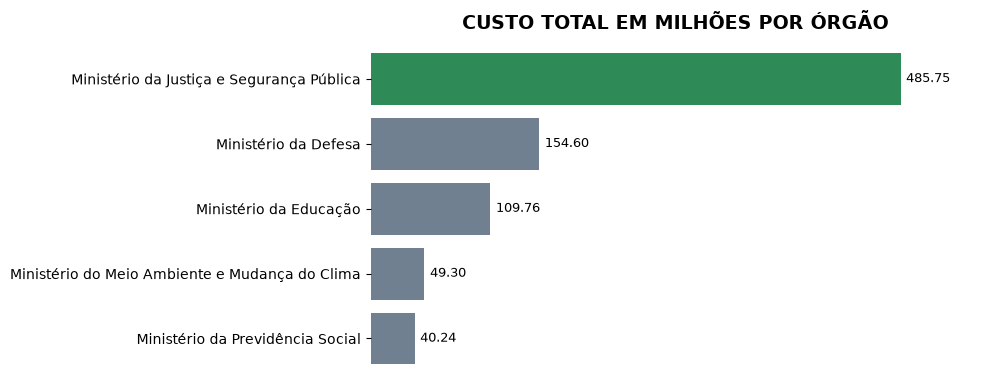

In [103]:
# Criação Gráfico Pergunta 1

fig, ax = plt.subplots(figsize=(10,4))
cores = ["seagreen"] + ["slategray"] * (len(tabela_1) - 1) # Destaca o primeiro órgão
barras = ax.barh(tabela_1["Órgão"],tabela_1["Custo em Milhões"],color=cores)
ax.bar_label(barras,fmt="%.2f",label_type="edge",padding=4,fontsize=9,color="black") # Custos logo após as barras
ax.set_title("CUSTO TOTAL EM MILHÕES POR ÓRGÃO",fontsize=14,fontweight="bold") # Título do gráfico
ax.invert_yaxis() # Mantem o primeiro órgão no topo
ax.set_xticks([]) # Retira os valores do eixo X
ax.margins(x=0.15) # Reserva espaço para os valores
for spine in ax.spines.values(): # Remover as linhas das bordas do gráfico
    spine.set_visible(False)

plt.savefig("Graficos/pergunta_1_custo_total_por_orgao.png",dpi=300,bbox_inches="tight")
plt.tight_layout()
plt.show()

In [104]:
# Conclusão Pergunta 1
primeiro_orgao = tabela_1["Órgão"].iloc[0]
primeiro_custo = tabela_1["Custo em Milhões"].iloc[0]

segundo_orgao = tabela_1["Órgão"].iloc[1]
segundo_custo = tabela_1["Custo em Milhões"].iloc[1]
diferenca_percentual = ((primeiro_custo - segundo_custo) / segundo_custo) * 100

outros_quatro = tabela_1["Custo em Milhões"].iloc[1:].sum()
percentual_soma = (primeiro_custo / outros_quatro) * 100

print(f"O orgão com o maior custo total foi '{primeiro_orgao}'.")
print(f"Com o custo total de {primeiro_custo:.2f} milhões de reais.")

print(
    f"O custo foi {diferenca_percentual:.2f}% maior "
    f"que o do segundo colocado, '{segundo_orgao}'."
)

print(
    f"O custo do primeiro órgão equivale a "
    f"{percentual_soma:.2f}% da soma dos custos "
    f"dos outros quatro órgãos do ranking."
)

O orgão com o maior custo total foi 'Ministério da Justiça e Segurança Pública'.
Com o custo total de 485.75 milhões de reais.
O custo foi 214.21% maior que o do segundo colocado, 'Ministério da Defesa'.
O custo do primeiro órgão equivale a 137.26% da soma dos custos dos outros quatro órgãos do ranking.


**PERGUNTA 2** - QUAIS SÃO OS 3 DESTINOS COM MAIOR CUSTO MÉDIO POR VIAGEM?

In [105]:
# Consulta SQL e criação Tabela Pergunta 2
# Para afins de análise foram considerados apenas destinos que possuem mais que 100 viagens

tabela_2 = consultar_sql("""
    SELECT
        destinos AS "Destino",
        COUNT(id_viagem) AS "Qtd Viagens",
        AVG(valor_total) AS "Custo Médio"
    FROM silver_viagem
    WHERE situacao = 'Realizada'
    GROUP BY destinos
    HAVING COUNT(id_viagem) > 100
    ORDER BY AVG(valor_total) DESC
    LIMIT 3
                           """)
tabela_2["Custo em Milhares"] = tabela_2["Custo Médio"] /1_000
display(tabela_2)

,Destino,Qtd Viagens,Custo Médio,Custo em Milhares
0,"Brasília/DF, Brasília/DF",283,27401.80,27.40
1,Genebra/Suíça,242,25469.22,25.47
2,Nova York/Estados Unidos da América,149,21214.19,21.21


### Atenção — interpretação dos resultados

- **Agrupamento dos destinos:** a coluna `destinos` pode conter várias cidades ou trajetos em um único texto. Dessa forma, cada combinação textual diferente é considerada um destino distinto na consulta, e não necessariamente uma cidade individual.
- **Quantidade mínima de viagens:** foram considerados apenas registros com mais de 100 viagens realizadas por combinação de destinos. Esse critério reduz a influência de casos com poucas observações, que podem apresentar custos médios elevados.
- **Limitação da análise:** os resultados representam o custo médio das viagens agrupadas por texto de destino. Para analisar cada cidade individualmente, seria necessário tratar e separar os destinos antes do agrupamento.

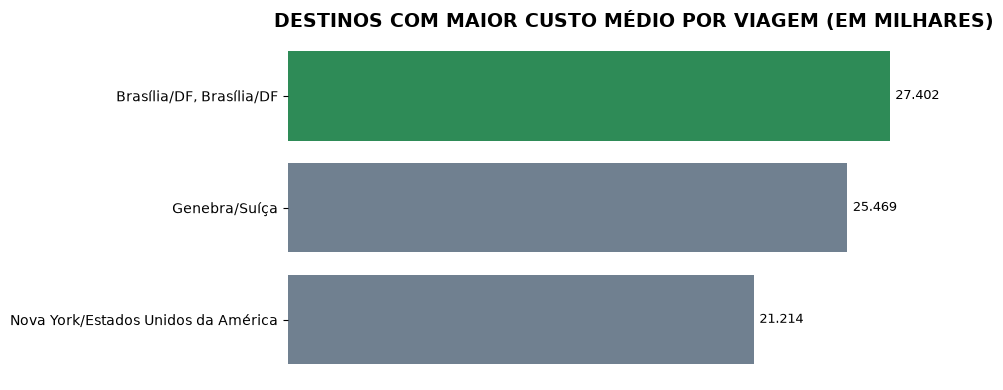

In [106]:
# Criação Gráfico Pergunta 2 

fig, ax = plt.subplots(figsize=(10,4))
cores = ["seagreen"] + ["slategray"] * (len(tabela_2) - 1) # Destaca o primeiro órgão
barras = ax.barh(tabela_2["Destino"],tabela_2["Custo em Milhares"],color=cores)
ax.bar_label(barras,fmt="%.3f",label_type="edge",padding=4,fontsize=9,color="black") # Custos logo após as barras
ax.set_title("DESTINOS COM MAIOR CUSTO MÉDIO POR VIAGEM (EM MILHARES)",fontsize=14,fontweight="bold") # Título do gráfico
ax.invert_yaxis() # Mantem o primeiro órgão no topo
ax.set_xticks([]) # Retira os valores do eixo X
ax.margins(x=0.15) # Reserva espaço para os valores
for spine in ax.spines.values(): # Remover as linhas das bordas do gráfico
    spine.set_visible(False)

plt.savefig("Graficos/pergunta_2_custo_medio_por_destino.png",dpi=300,bbox_inches="tight")
plt.tight_layout()
plt.show()

In [107]:
# Conclusão Pergunta 2

primeiro_destino = tabela_2["Destino"].iloc[0]
primeiro_custo = tabela_2["Custo em Milhares"].iloc[0]
primeiro_qtd = tabela_2["Qtd Viagens"].iloc[0]

print(
    f"O destino com maior custo médio por viagem foi "
    f"'{primeiro_destino}', com custo médio de "
    f"R$ {primeiro_custo:.3f} mil."
)

print(
    f"Esse resultado considera {primeiro_qtd} viagens realizadas "
    f"para essa combinação de destinos."
)

print(
    "\nA análise considerou apenas destinos com mais de 100 viagens, "
    "reduzindo a influência de grupos com poucas observações."
)

print(
    "É importante observar que a coluna 'destinos' pode reunir várias cidades em um único texto." 
    "\nPortanto, o resultado representa uma combinação de destinos, e não necessariamente uma cidade individual."
)


O destino com maior custo médio por viagem foi 'Brasília/DF, Brasília/DF', com custo médio de R$ 27.402 mil.
Esse resultado considera 283 viagens realizadas para essa combinação de destinos.

A análise considerou apenas destinos com mais de 100 viagens, reduzindo a influência de grupos com poucas observações.
É importante observar que a coluna 'destinos' pode reunir várias cidades em um único texto.
Portanto, o resultado representa uma combinação de destinos, e não necessariamente uma cidade individual.


**PERGUNTA 3** - QUAL VIAGEM DE MAIOR DURAÇÃO E O SEU CUSTO TOTAL?

In [108]:
# Consulta SQL e criação Tabela Pergunta 3

tabela_3 = consultar_sql("""
    SELECT
        id_viagem AS "ID Viagem",
        nome_orgao_superior AS "Órgão",
        data_inicio AS "Data Início",
        data_fim AS "Data Fim",
        duracao_dias AS "Duração (dias)",
        valor_total AS "Custo Total"
    FROM silver_viagem
    WHERE situacao = 'Realizada' 
        AND duracao_dias IS NOT NULL
    ORDER BY duracao_dias DESC
    LIMIT 2    
                               """)
display(tabela_3)

,ID Viagem,Órgão,Data Início,Data Fim,Duração (dias),Custo Total
0,0000000000020699856,Ministério da Previdência Social,2025-01-13,2026-01-31,384,0.00
1,0000000000020793594,Ministério da Justiça e Segurança Pública,2025-01-02,2026-01-15,379,120650.00


### Atenção — interpretação dos resultados

A viagem com a maior duração registrada apresentou custo total igual a R$ 0,00. Com os dados disponíveis, não é possível determinar se esse valor decorre de uma falha de preenchimento ou se representa efetivamente uma viagem sem custos registrados.  
Por esse motivo, a analise foi realizada olhando as duas viagens com maior duração.

In [109]:
# Consulta SQL e criação da média da duração das outras viagens Pergunta 3

media_duracao = consultar_sql("""
    WITH viagens_classificadas AS (
        SELECT
            id_viagem,
            duracao_dias,
            ROW_NUMBER() OVER (
                ORDER BY duracao_dias DESC, id_viagem
            ) AS posicao
        FROM silver_viagem
        WHERE situacao = 'Realizada'
          AND duracao_dias IS NOT NULL
    )
    SELECT
        AVG(duracao_dias) AS "Média de Duração"
    FROM viagens_classificadas
    WHERE posicao > 2
""")

media_dias = media_duracao["Média de Duração"].iloc[0]

print(
    f"Média de duração das demais viagens: "
    f"{media_dias:.0f} dias"
)

Média de duração das demais viagens: 8 dias


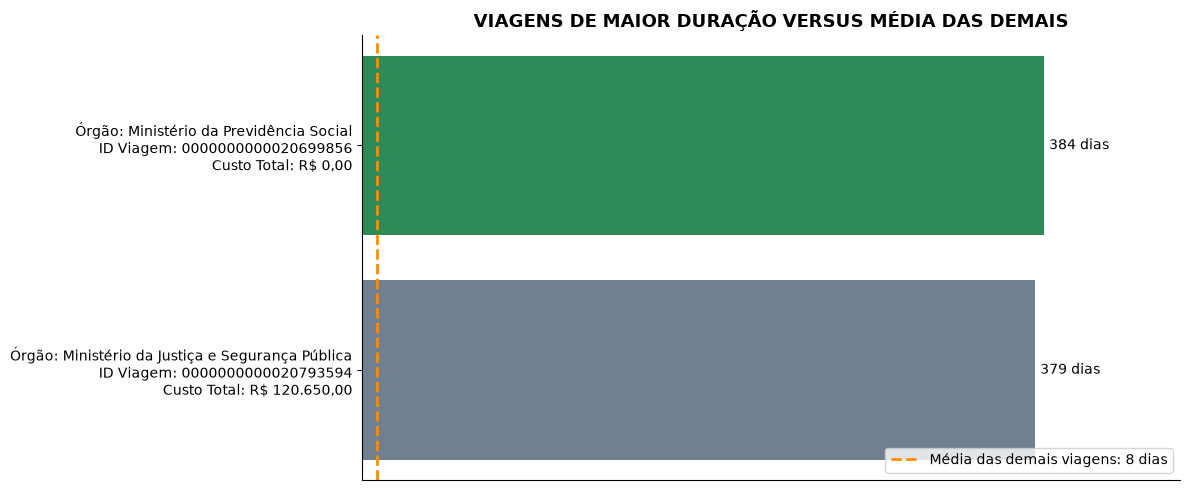

In [110]:
# Criação Gráfico Pergunta 3
rotulos = [
    f"Órgão: {orgao}\n"
    f"ID Viagem: {id_viagem}\n"
    f"Custo Total: R$ {formatar_numero(custo)}"
    for orgao, id_viagem, custo in zip(
        tabela_3["Órgão"],
        tabela_3["ID Viagem"],
        tabela_3["Custo Total"]
    )
]

duracoes = tabela_3["Duração (dias)"].tolist()
fig, ax = plt.subplots(figsize=(12, 5))
barras = ax.barh(rotulos,duracoes,color=["seagreen", "slategray"][:len(duracoes)])

# Linha de referência da média das demais viagens
ax.axvline(
    media_dias,
    color="darkorange",
    linestyle="--",
    linewidth=2,
    label=f"Média das demais viagens: {media_dias:.0f} dias"
)

# Identificação da duração e do custo
for barra, duracao in zip(barras,duracoes):
    ax.text(
        barra.get_width() + 3,
        barra.get_y() + barra.get_height() / 2,
        f"{duracao} dias",
        va="center",
        fontsize=10
    )

ax.set_title(
    "VIAGENS DE MAIOR DURAÇÃO VERSUS MÉDIA DAS DEMAIS",
    fontsize=13,
    fontweight="bold"
)

ax.invert_yaxis()
ax.legend(loc="lower right")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.margins(x=0.20)
ax.set_xticks([]) # Retira os valores do eixo X

plt.savefig("Graficos/pergunta_3_duracao_viagens.png",dpi=300,bbox_inches="tight")
plt.tight_layout()
plt.show()

In [111]:
# Conclusão Pergunta 3

for _, viagem in tabela_3.iterrows():
    duracao = viagem["Duração (dias)"]
    diferenca = duracao - media_dias
    multiplicador = duracao / media_dias

    print(
        f"A viagem de ID `{viagem['ID Viagem']}` teve duração "
        f"de {duracao} dias, {diferenca:.0f} dias acima "
        f"da média das demais viagens."
    )
    print(
        f"Sua duração corresponde a {multiplicador:.0f} "
        f"vezes a média de duração.\n"
    )
    
print(
    f"A duração média das demais viagens realizadas foi de "
    f"{media_dias:.0f} dias."
)


A viagem de ID `0000000000020699856` teve duração de 384 dias, 376 dias acima da média das demais viagens.
Sua duração corresponde a 47 vezes a média de duração.

A viagem de ID `0000000000020793594` teve duração de 379 dias, 371 dias acima da média das demais viagens.
Sua duração corresponde a 47 vezes a média de duração.

A duração média das demais viagens realizadas foi de 8 dias.


**PERGUNTA 4** - QUAIS OS TIPOS DE PAGAMENTO E O VALOR MÉDIO DE CADA?  
Criado tabela gold_ ....

**PERGUNTA 5** - QUAIS SÃO OS MEIOS DE TRANSPORTES MAIS UTILIZADO?  
Criado tabela gold_ .....

**PERGUNTA 6** - QUAIS UF's DE DESTINO APARECEM EM MAIS TRECHOS?

**PERGUNTA 7** - QUAL ORGÃO PAGOU MAIS NO TOTAL?

### PERGUNTAS EXTRAS
**PERGUNTA 1** - QUAL VIAJANTE PAGOU MAIS NO TOTAL? QUAL A QUANTIDADE DE VIAGEM E A MÉDIA POR VIAGEM?  
**PERGUNTA 2** - QUAL O CUSTO TOTAL DAS VIAGENS POR MÊS?  
**PERGUNTA 3** - QUAIS ORGÃOS REALIZARAM MAIS VIAGENS, POR MÊS?  
**PERGUNTA 4** - QUAL O CUSTO MÉDIO POR VIAGEM DE CADA ORGÃO?  
**PERGUNTA 5** - QUAL A QUANTIDADE DE TECHOS POR VIAGEM E A MÉDIA?  
**PERGUNTA 6** - QUAL A QUANTIDADE E CUSTO TOTAL PARA VIAGENS NACIONAS E INTERNACIONAIS?  

### Andamento da análise

A análise está em andamento. As três primeiras perguntas de negócio já foram respondidas utilizando consultas SQL sobre a camada Silver, com resultados organizados em tabelas, gráficos e conclusões no notebook `3_analise.ipynb`.

As análises consideram apenas viagens com situação **`Realizada`**, conforme a regra de negócio definida para o projeto.

| Pergunta | Análise realizada | Visualização |
|---|---|---|
| 1 | Cinco órgãos com maior custo total de viagens | `pergunta_1_custo_total_por_orgao.png` |
| 2 | Três combinações de destinos com maior custo médio por viagem, considerando apenas grupos com mais de 100 viagens realizadas | `pergunta_2_custo_medio_por_destino.png` |
| 3 | Duas viagens de maior duração, comparadas à duração média das demais viagens realizadas | `pergunta_3_duracao_viagens.png` |

**Observações metodológicas:**

- Na pergunta 2, a coluna `destinos` pode conter várias cidades em um mesmo texto. Portanto, o agrupamento representa combinações textuais de destinos, não necessariamente cidades individuais.
- Na pergunta 3, a viagem de maior duração apresentou custo total igual a zero, enquanto a segunda apresentou custo de R$ 120.650,00. O valor zero foi sinalizado como um ponto de atenção, sem presumir que seja um erro de preenchimento.
- A análise continua em desenvolvimento. As demais perguntas, as estruturas previstas para a camada Gold e as conclusões gerais serão documentadas conforme forem concluídas.